# Representação Semântica de Frases com Embeddings 2

##### Sete frases, as três primeiras falam sobre o gato dormindo, as próximas três falam sobre comida/restaurante, a última retorna para o assunto do gato

### Geração de Embeddings

In [1]:
import numpy as np
from sentence_transformers import SentenceTransformer


sentences = [
    "O gato dormiu no sofá.",
    "O gato estava muito cansado.",
    "Por isso não quis brincar."
    "Vamos comer?",
    "Aonde você que ir?",
    "Quero comer sushi, vamos no restaurante japônes.",
    "O gato vai dormir por horas"
]

model = SentenceTransformer('paraphrase-multilingual-MiniLM-L12-v2')
S = model.encode(sentences)

print("\nEmbeddings (S):")
print(S.shape)  # (3, d)
print(S)

c:\Users\sofia\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 16003.88it/s]
BertModel LOAD REPORT from: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Embeddings (S):
(6, 384)
[[ 0.47853285 -0.16353989 -0.02593613 ... -0.02797373  0.2828926
  -0.16273977]
 [ 0.5269687  -0.139731    0.14509504 ... -0.16153657 -0.12665938
  -0.22428213]
 [ 0.32392782  0.13044353  0.317417   ...  0.01767128 -0.02723703
  -0.09020385]
 [ 0.6808149  -0.1873465   0.20440042 ...  0.00821622 -0.18320021
  -0.07189853]
 [ 0.28321213 -0.10044068 -0.03595542 ... -0.10332821 -0.23413722
  -0.13979882]
 [ 0.24766257 -0.15480915  0.05230742 ... -0.24321762  0.06123092
  -0.21196525]]


### Construção da Matriz de Adjacência

In [2]:
from sklearn.metrics.pairwise import cosine_similarity

scores = cosine_similarity(S)

n = len(sentences)
A = np.zeros((n, n))

for i in range(n):
    for j in range(n):
        if j < i: 
            A[i, j] = scores[i, j]

print(A)

[[ 0.          0.          0.          0.          0.          0.        ]
 [ 0.62801445  0.          0.          0.          0.          0.        ]
 [ 0.04429856  0.11895115  0.          0.          0.          0.        ]
 [-0.10135736  0.01129747  0.31878424  0.          0.          0.        ]
 [-0.06357832 -0.07904621  0.37655717  0.24257553  0.          0.        ]
 [ 0.60843468  0.79606485  0.04848631 -0.01723117 -0.07355009  0.        ]]


### Grafo

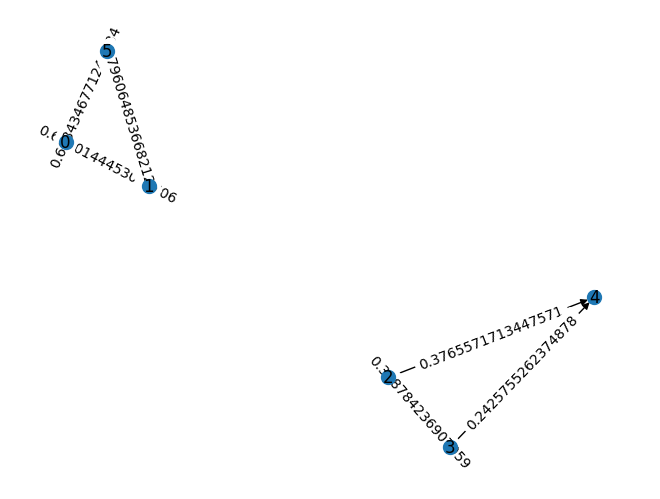

In [3]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.DiGraph()

for i, s in enumerate(sentences):
    G.add_node(i, label=s)

for i in range(n):
    for j in range(n):
        weight = A[i, j]
        if weight > 0.2:  
            G.add_edge(j, i, weight=weight) 

pos = nx.spring_layout(G)

nx.draw(G, pos, with_labels=True, node_size=100)
labels = nx.get_edge_attributes(G, 'weight')
nx.draw_networkx_edge_labels(G, pos, edge_labels=labels)

plt.show()

O gato dormiu no sofá. → Cluster 1
O gato estava muito cansado. → Cluster 1
Por isso não quis brincar.Vamos comer? → Cluster 0
Aonde você que ir? → Cluster 0
Quero comer sushi, vamos no restaurante japônes. → Cluster 0
O gato vai dormir por horas → Cluster 1


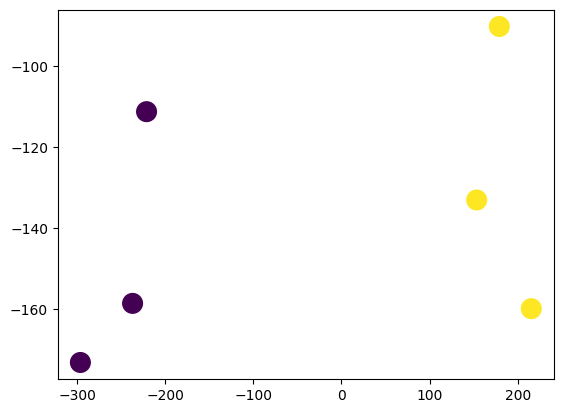

In [4]:
from sklearn.cluster import SpectralClustering
from sklearn.manifold import TSNE

similarity = S @ S.T
tsne = TSNE(n_components=2, random_state=0, perplexity=2)
S_2d = tsne.fit_transform(S)

clustering = SpectralClustering(
    n_clusters=2,
    affinity='precomputed', 
    random_state=0
)

labels = clustering.fit_predict(similarity)

for i, s in enumerate(sentences):
    print(f"{s} → Cluster {labels[i]}")


plt.scatter(S_2d[:,0], S_2d[:,1], c=labels, s=200)